## Download data

In [3]:
!curl -o ../data/weinreb/stateFate_inVitro_normed_counts.mtx.gz https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/stateFate_inVitro_normed_counts.mtx.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 1969M  100 1969M    0     0  20.1M      0  0:01:37  0:01:37 --:--:-- 18.1MM    0     0  21.1M      0  0:01:33  0:00:15  0:01:18 22.2M   0     0  21.5M      0  0:01:31  0:00:31  0:01:00 22.8M   0     0  21.7M      0  0:01:30  0:00:44  0:00:46 22.0M0     0  20.9M      0  0:01:34  0:00:53  0:00:41 16.3MM    0     0  20.7M      0  0:01:35  0:01:07  0:00:28 21.6M    0     0  20.7M      0  0:01:34  0:01:09  0:00:25 21.9M


In [4]:
!curl -o ../data/weinreb/stateFate_inVitro_gene_names.txt.gz https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/stateFate_inVitro_gene_names.txt.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 65687  100 65687    0     0   493k      0 --:--:-- --:--:-- --:--:--  497k


In [5]:
!curl -o ../data/weinreb/stateFate_inVitro_clone_matrix.mtx.gz https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/stateFate_inVitro_clone_matrix.mtx.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  193k  100  193k    0     0  1171k      0 --:--:-- --:--:-- --:--:-- 1177k


In [6]:
!curl -o ../data/weinreb/stateFate_inVitro_metadata.txt.gz https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/stateFate_inVitro_metadata.txt.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 2162k  100 2162k    0     0  5516k      0 --:--:-- --:--:-- --:--:-- 5516k


In [7]:
!curl -o ../data/weinreb/stateFate_inVitro_neutrophil_pseudotime.txt.gz https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/stateFate_inVitro_neutrophil_pseudotime.txt.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  304k  100  304k    0     0  1250k      0 --:--:-- --:--:-- --:--:-- 1253k


In [8]:
!curl -o ../data/weinreb/stateFate_inVitro_neutrophil_monocyte_trajectory.txt.gz https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/stateFate_inVitro_neutrophil_monocyte_trajectory.txt.gz

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  213k  100  213k    0     0  1157k      0 --:--:-- --:--:-- --:--:-- 1157k


## Explore data

In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.io
import scipy.sparse as sp

In [2]:
DATA_DIR = "../data/weinreb"

In [3]:
X = scipy.io.mmread(f"{DATA_DIR}/stateFate_inVitro_normed_counts.mtx.gz").tocsr()

In [4]:
genes = pd.read_csv(
    f"{DATA_DIR}/stateFate_inVitro_gene_names.txt.gz",
    header=None,
    sep="\t"
)[0].values

In [5]:
meta = pd.read_csv(
    f"{DATA_DIR}/stateFate_inVitro_metadata.txt.gz",
    sep="\t"
)
meta

,Library,Cell barcode,Time point,Starting population,Cell type annotation,Well,SPRING-x,SPRING-y
0,d6_2_2,GCGTGCAA-AGAAGTTA,6.0,Lin-Kit+Sca1-,Undifferentiated,2,411.496,-96.190
1,d6_2_2,AAGGGACC-CTCGATGC,6.0,Lin-Kit+Sca1-,Undifferentiated,2,-587.462,-306.925
2,d6_2_2,CGTACCGA-AGCGCCTT,6.0,Lin-Kit+Sca1-,Monocyte,2,1429.805,-429.300
3,d6_2_2,CTGAAGGG-AGGAGCTT,6.0,Lin-Kit+Sca1-,Neutrophil,2,1150.028,-2030.369
4,d6_2_2,CCGTAGCT-AGGCAGTT,6.0,Lin-Kit+Sca1-,Undifferentiated,2,-1169.594,362.010
...,...,...,...,...,...,...,...,...
130882,LSK_d6_1_3,TCTGATTT-CGGGCTTT,6.0,Lin-Kit+Sca1+,Undifferentiated,1,-308.468,-163.223
130883,LSK_d6_1_3,AGTCACAA-TGTGTCCT,6.0,Lin-Kit+Sca1+,Undifferentiated,1,-3.435,575.133
130884,LSK_d6_1_3,GGAGGTTT-AGGCAGTT,6.0,Lin-Kit+Sca1+,Monocyte,1,2548.309,24.683
130885,LSK_d6_1_3,CCGGAAAT-GGGAAGGT,6.0,Lin-Kit+Sca1+,Monocyte,1,2658.601,131.098


In [6]:
adata = sc.AnnData(X=X)
adata.var_names = genes
adata.obs = meta.copy()

/opt/homebrew/Cellar/python@3.13/3.13.7/Frameworks/Python.framework/Versions/3.13/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [7]:
spring_coords = meta[["SPRING-x", "SPRING-y"]].values
adata.obsm["X_spring"] = spring_coords

In [8]:
clone_mat = scipy.io.mmread(
    f"{DATA_DIR}/stateFate_inVitro_clone_matrix.mtx.gz"
).tocsr()

adata.obsm["X_clone"] = clone_mat

In [9]:
pt = pd.read_csv(
    f"{DATA_DIR}/stateFate_inVitro_neutrophil_pseudotime.txt.gz",
    sep="\t"
)

adata.obs["neutrophil_pseudotime"] = np.nan
adata.obs.iloc[pt.iloc[:,0], adata.obs.columns.get_loc("neutrophil_pseudotime")] = pt.iloc[:,1].values

In [10]:
mapping = {
    "Ccr7_DC": "DC",
    "pDC": "DC",
}

adata.obs["cell_type_collapsed"] = (
    adata.obs["Cell type annotation"]
    .replace(mapping)
)


In [11]:
adata

AnnData object with n_obs × n_vars = 130887 × 25289
    obs: 'Library', 'Cell barcode', 'Time point', 'Starting population', 'Cell type annotation', 'Well', 'SPRING-x', 'SPRING-y', 'neutrophil_pseudotime', 'cell_type_collapsed'
    obsm: 'X_spring', 'X_clone'

In [12]:
import seaborn as sns
import numpy as np

my_palette_collapsed = {
    'Undifferentiated': '#E5E4E2',
    'Monocyte': sns.color_palette()[0],
    'Neutrophil': sns.color_palette()[1],
    'Baso': sns.color_palette()[2],
    'Eos': sns.color_palette()[3],
    'Mast': sns.color_palette()[4],
    'Meg': sns.color_palette()[5],
    'Erythroid': sns.color_palette()[6],
    'Lymphoid': sns.color_palette()[8],
    'DC': sns.color_palette()[9],
}


In [13]:
adata.obs["cell_type_collapsed"] = adata.obs["cell_type_collapsed"].astype("category")

cats = adata.obs["cell_type_collapsed"].cat.categories
adata.uns["cell_type_collapsed_colors"] = [
    my_palette_collapsed[c] for c in cats
]


/Users/samin/workspace/phylodynamic-carta/.venv/lib/python3.13/site-packages/scanpy/plotting/_tools/scatterplots.py:1148: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter([], [], c=palette[label], label=label)


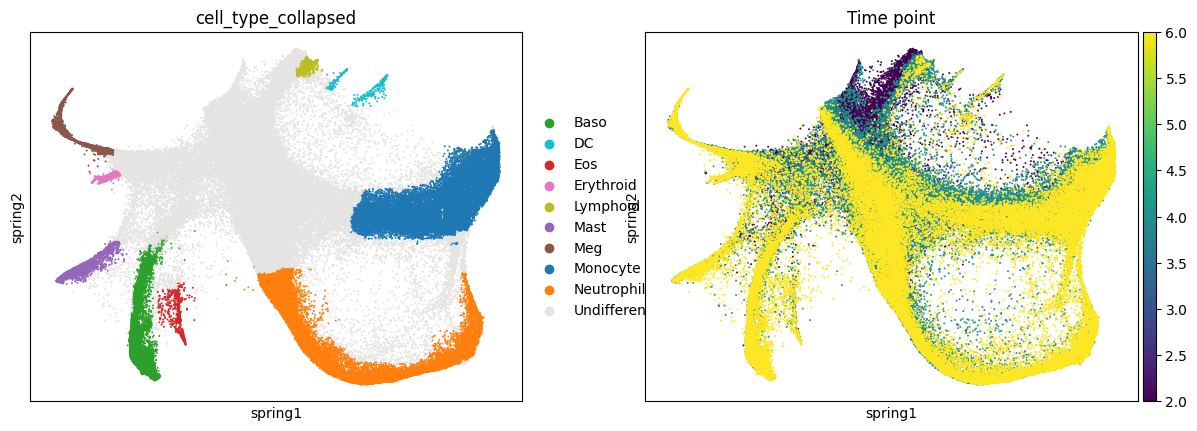

In [14]:
sc.pl.embedding(
    adata,
    basis="spring",
    color=["cell_type_collapsed", "Time point",],
    size=8
)

In [15]:
counts = (
    adata.obs
    .groupby(["Time point", "cell_type_collapsed"])
    .size()
    .reset_index(name="n")
)

counts["percent"] = (
    counts["n"]
    / counts.groupby("Time point")["n"].transform("sum")
    * 100
)

counts

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_77658/670687488.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["Time point", "cell_type_collapsed"])


,Time point,cell_type_collapsed,n,percent
0,2.0,Baso,187,0.661970
1,2.0,DC,73,0.258416
2,2.0,Eos,15,0.053099
3,2.0,Erythroid,100,0.353995
4,2.0,Lymphoid,144,0.509753
5,2.0,Mast,40,0.141598
6,2.0,Meg,97,0.343375
7,2.0,Monocyte,950,3.362951
8,2.0,Neutrophil,1068,3.780665
9,2.0,Undifferentiated,25575,90.534178


### Construct tree from CARTA

In [16]:
import networkx as nx

In [24]:
T = nx.DiGraph()

edges = [
    ('MPPb', 'MEP'),
    ('MPPb', 'MPPc'),
    ('MEP', 'Meg'),
    ('MEP', 'Erythroid'),
    ('MPPc', 'CMP'),
    ('MPPc', 'DC'),
    ('MPPc', 'Lymphoid'),
    ('CMP', 'Mast'),
    ('CMP', 'Myeloblast'),
    ('Myeloblast', '0'),
    ('Myeloblast', '1'),
    ('0', 'Baso'),
    ('0', 'Eos'),
    ('1', 'Neutrophil'),
    ('1', 'Monocyte'),
]

T.add_edges_from(edges)

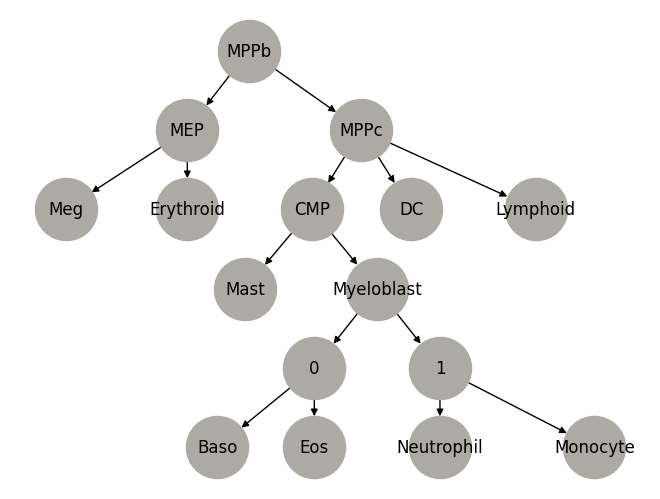

In [25]:
import matplotlib.pyplot as plt
from networkx.drawing.nx_agraph import graphviz_layout

pos = graphviz_layout(T, prog="dot")  # dot = hierarchical layout

nx.draw(T, pos, with_labels=True, node_size=2000, node_color="#ADAAA3")
plt.show()

In [ ]:
from typing import List

def linearize_parameters(
        birth_rate: float,
        death_rate: float,
        differentiation_rates: dict[float],
        commitment_biases: dict[str, dict[str, float]]
):
    x = [

    ]
    return np.array(x)

In [12]:
barcoded_cells = np.where(clone_mat.sum(axis=1).A1 > 0)[0]

In [13]:
import pandas as pd

row_sums = clone_mat.sum(axis=1).A1
counts = pd.Series(row_sums.astype(int)).value_counts().sort_index()
counts

0    81585
1    49302
Name: count, dtype: int64

In [ ]:
import numpy as np

collapsed = np.full(clone_mat.shape[0], np.nan)

rows, cols = clone_mat.nonzero()
collapsed[rows] = cols
collapsed

array([ 573., 1440.,  394., ...,   nan,   nan,   nan], shape=(130887,))

In [16]:
import pandas as pd

value_counts = pd.Series(collapsed).value_counts(dropna=True)
value_counts

1261.0    177
2370.0    165
5714.0    142
292.0     134
5209.0    130
         ... 
5594.0      2
866.0       2
4884.0      2
5101.0      2
2251.0      2
Name: count, Length: 5864, dtype: int64

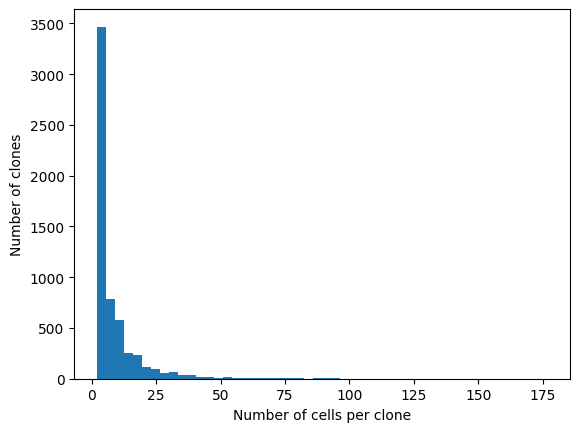

In [17]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(value_counts.values, bins=50)
plt.xlabel("Number of cells per clone")
plt.ylabel("Number of clones")
plt.show()
